In [ ]:
import os
from collections.abc import Callable
from pathlib import Path
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import seaborn as sns
import sys
sys.path.insert(0, str(Path.cwd().parent))

from src.encoder import DummyEncoder
from src import quant



In [2]:
data_dir = Path("../data")
chunks = pd.read_csv(data_dir / "chunks.csv")
questions = pd.read_csv(data_dir / "questions.csv")
answer_chunks = pd.read_csv(data_dir / "answer_chunks.csv")

chunks.head()

,chunk_id,pid,chunk_no,start,end,text
0,0,0,0,0,127,"Architecturally, the school has a Catholic cha..."
1,1,0,1,54,270,Atop the Main Building's gold dome is a golden...
2,2,0,2,128,333,Immediately in front of the Main Building and ...
3,3,0,3,271,421,Next to the Main Building is the Basilica of t...
4,4,0,4,334,550,"Immediately behind the basilica is the Grotto,..."


In [3]:
model_name = "BAAI/bge-small-en-v1.5"
save_dir = data_dir / f"embeddings_{model_name.rsplit('/', 1)[-1]}"

chunk_ids = np.load(save_dir / "chunk_ids.npy")
chunk_embeddings = np.load(save_dir / "chunk_embeddings.npy")
query_ids = np.load(save_dir / "query_ids.npy")
query_embeddings = np.load(save_dir / "query_embeddings.npy")

chunks = chunks.set_index("chunk_id", drop=False).loc[chunk_ids].reset_index(drop=True)
questions = questions.set_index("qid", drop=False).loc[query_ids].reset_index(drop=True)


In [4]:
encoder = DummyEncoder(
    chunk_texts=chunks["text"].tolist(),
    chunk_embeddings=chunk_embeddings,
    query_texts=questions["question"].tolist(),
    query_embeddings=query_embeddings,
)


In [5]:
def exact_search(
    query_embeddings: np.ndarray,
    chunk_embeddings: np.ndarray,
    chunk_ids: np.ndarray,
    k: int = 10,
    batch_size: int = 64,
) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает ID и оценки top-k фрагментов для каждого вопроса."""
    top_ids = []
    top_scores = []

    for start in range(0, len(query_embeddings), batch_size):
        scores = query_embeddings[start:start + batch_size] @ chunk_embeddings.T
        candidates = np.argpartition(scores, -k, axis=1)[:, -k:]
        candidate_scores = np.take_along_axis(scores, candidates, axis=1)
        order = np.argsort(-candidate_scores, axis=1)
        positions = np.take_along_axis(candidates, order, axis=1)

        top_ids.append(chunk_ids[positions])
        top_scores.append(np.take_along_axis(scores, positions, axis=1))

    return np.concatenate(top_ids), np.concatenate(top_scores)

In [6]:
K=25
if not os.path.isfile(save_dir / f"exact_top{K}_chunk_ids.npy"):
    exact_ids, exact_scores = exact_search(query_embeddings, chunk_embeddings, chunk_ids, k=K)

    np.save(save_dir / f"exact_top{K}_chunk_ids.npy", exact_ids)
    np.save(save_dir / f"exact_top{K}_scores.npy", exact_scores)
else:
    exact_ids = np.load(save_dir / f"exact_top{K}_chunk_ids.npy")
    exact_scores = np.load(save_dir / f"exact_top{K}_scores.npy")

In [7]:
def hit(retrieved: set[int], relevant: set[int]) -> float:
    """Есть ли среди найденных фрагментов хотя бы один эталонный."""
    return float(len(retrieved & relevant) > 0)


def precision(retrieved: set[int], relevant: set[int]) -> float:
    """Доля эталонных фрагментов среди найденных."""
    return len(retrieved & relevant) / len(retrieved)


def recall(retrieved: set[int], relevant: set[int]) -> float:
    """Доля найденных фрагментов среди всех эталонных."""
    return len(retrieved & relevant) / len(relevant)


def calculate_metrics(
    top_ids: np.ndarray,
    questions: pd.DataFrame,
    answer_chunks: pd.DataFrame,
    metric_fn: Callable[[set[int], set[int]], float],
    ks: tuple[int,...] = (1, 5, 10),
) -> pd.DataFrame:
    """Усредняет выбранную метрику по строгому и мягкому эталонам."""
    metrics = {}
    for name, gold in (
        ("strict", answer_chunks[answer_chunks["is_annotated"]]),
        ("soft", answer_chunks),
    ):
        gold_chunks = gold.groupby("orig_qid")["chunk_id"].agg(set).to_dict()
        metrics[name] = []
        for k in ks:
            values = [
                metric_fn(set(row[:k]), gold_chunks[orig_qid])
                for orig_qid, row in zip(questions["orig_qid"], top_ids)
            ]
            metrics[name].append(np.mean(values))

    return pd.DataFrame(metrics, index=pd.Index(ks, name="k"))

In [8]:
train_mask = (questions["role"] == "train") & ~questions["is_paraphrase"]
results = {}
for metric_fn in (hit, precision, recall):
    results[metric_fn.__name__] = calculate_metrics(
        exact_ids[train_mask], questions[train_mask], answer_chunks,
        metric_fn=metric_fn, ks=(1,5,10,15,20,25),
    )

metrics = pd.concat(results, names=["metric", "k"], axis=1)
metrics

metric       hit           precision              recall          
k         strict      soft    strict      soft    strict      soft
k                                                                 
1       0.634024  0.639789  0.634024  0.639789  0.469188  0.451656
5       0.823451  0.827275  0.226515  0.232876  0.769139  0.748778
10      0.870679  0.873921  0.122510  0.127089  0.828908  0.810351
15      0.892312  0.895235  0.084473  0.088013  0.856283  0.838851
20      0.906046  0.908660  0.064676  0.067592  0.873499  0.856897
25      0.915601  0.918124  0.052509  0.054993  0.885942  0.870032

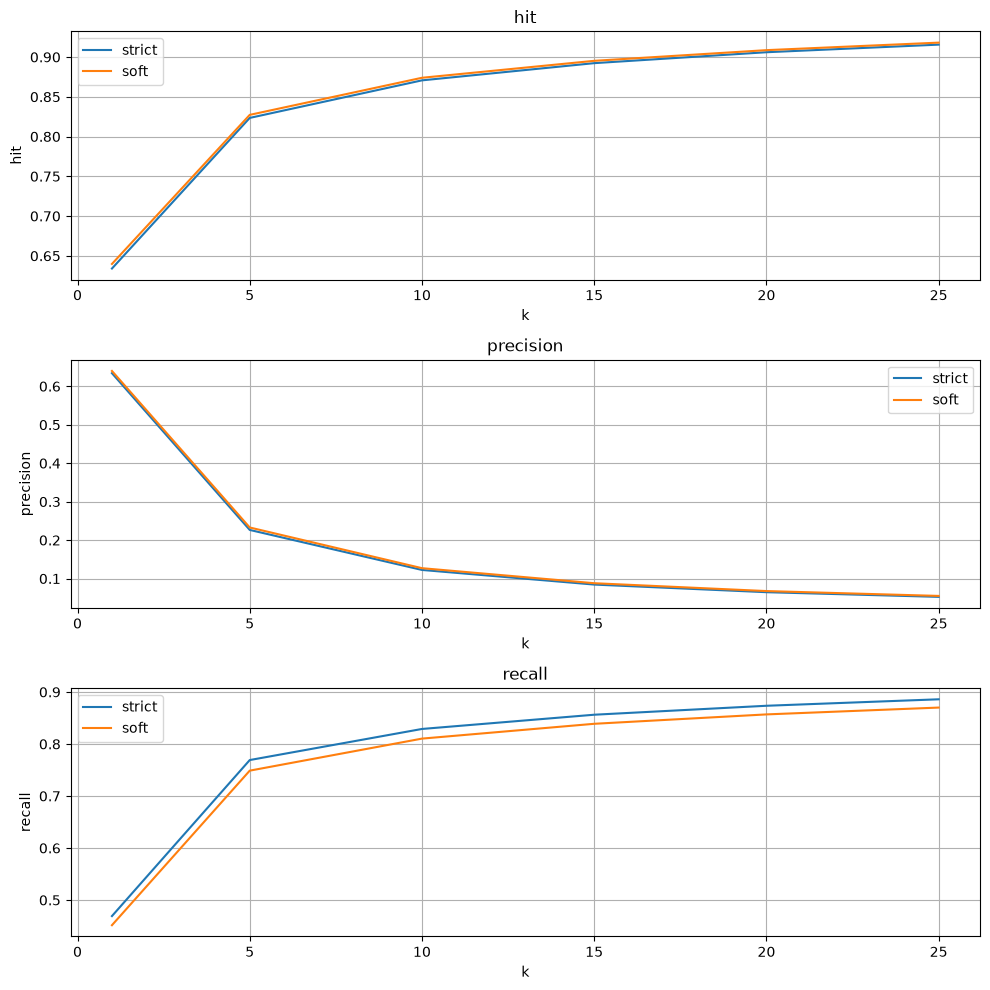

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

for ax, metric_name in zip(axes, ["hit", "precision", "recall"]):
    data = metrics[metric_name].reset_index()

    sns.lineplot(data=data, x="k", y="strict", label="strict", ax=ax)
    sns.lineplot(data=data, x="k", y="soft", label="soft", ax=ax)

    ax.set_title(metric_name)
    ax.set_ylabel(metric_name)
    ax.grid(True)
    
fig.tight_layout()
plt.show()

In [10]:
def evaluate_quantization(
    query_embeddings: np.ndarray,
    chunk_embeddings: np.ndarray,
    chunk_ids: np.ndarray,
    chunks: pd.DataFrame,
    questions: pd.DataFrame,
    answer_chunks: pd.DataFrame,
    metric_fn: Callable[[set[int], set[int]], float],
    quantizer: quant.BaseQuant,
    ks: tuple[int, ...] = (1, 5, 10),
) -> pd.DataFrame:
    """Обучает квантизатор на train-фрагментах и считает метрики train/valid.

    Эмбеддинги соответствуют порядку строк questions и chunks.
    Поиск идёт по всей базе без нормализации восстановленных векторов.
    Метрики исходных вопросов (real) и перефразов (paraphrase) считаются отдельно.
    """
    train_pids = questions.loc[questions["role"] == "train", "pid"]
    chunk_train_mask = chunks["pid"].isin(train_pids).to_numpy()
    quantizer.fit(chunk_embeddings[chunk_train_mask])
    codes = quantizer.quant(chunk_embeddings)
    reconstructed_embeddings = quantizer.dequant(codes)
    top_ids, _ = exact_search(
        query_embeddings, reconstructed_embeddings, chunk_ids,
        k=max(ks),
    )
    results = []
    for role in ("train", "valid"):
        for question_type, is_paraphrase in (("real", False), ("paraphrase", True)):
            mask = (
                (questions["role"] == role)
                & (questions["is_paraphrase"] == is_paraphrase)
            ).to_numpy()
            group_metrics = calculate_metrics(
                top_ids[mask], questions.loc[mask], answer_chunks, metric_fn, ks,
            )
            group_metrics.columns = [
                f"{role}_{name}_{question_type}" for name in group_metrics.columns
            ]
            results.append(group_metrics)
    return pd.concat(results, axis=1)


In [11]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.BaseQuant(),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.469188,0.451656,0.34225,0.329042,0.460404,0.436215,0.324667,0.318038
5,0.769139,0.748778,0.61750,0.599058,0.766831,0.737614,0.601833,0.590627
10,0.828908,0.810351,0.70575,0.686250,0.829147,0.802350,0.688833,0.671449
15,0.856283,0.838851,0.74475,0.726892,0.856895,0.831816,0.729333,0.708613
20,0.873499,0.856897,0.77550,0.757925,0.872157,0.848781,0.761000,0.740668
25,0.885942,0.870032,0.79475,0.777583,0.886224,0.864467,0.779333,0.760124


In [12]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.SqQuant(num_bits=8),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.469068,0.451574,0.34025,0.327042,0.459773,0.435580,0.324000,0.317371
5,0.769048,0.748711,0.61750,0.599333,0.767919,0.738357,0.602333,0.588527
10,0.828617,0.810048,0.70175,0.682000,0.829655,0.802965,0.682500,0.665783
15,0.856306,0.838904,0.74575,0.727725,0.856824,0.831790,0.735333,0.714279
20,0.873590,0.857000,0.77400,0.756325,0.872362,0.849083,0.764000,0.744002
25,0.886245,0.870348,0.79550,0.778333,0.885151,0.863371,0.781333,0.761057


In [13]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.SqQuant(num_bits=4),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.433764,0.417877,0.29725,0.286342,0.427066,0.405478,0.294167,0.289352
5,0.732545,0.713049,0.56525,0.548775,0.733371,0.705342,0.568833,0.555227
10,0.799494,0.781116,0.64625,0.629358,0.801801,0.774993,0.642833,0.626549
15,0.831414,0.813901,0.69200,0.674725,0.834765,0.808768,0.693333,0.677183
20,0.851163,0.834448,0.72575,0.708817,0.855798,0.831547,0.726167,0.707210
25,0.865222,0.849091,0.75550,0.738958,0.868757,0.845881,0.754167,0.737010


In [14]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.PqQuant(num_bits=8, num_parts=192),
    ks=(1, 5, 10, 15, 20, 25),
)

KeyboardInterrupt: 

In [ ]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.SqQuant(num_bits=2),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.090358,0.087464,0.04600,0.043875,0.083873,0.080098,0.044333,0.042733
5,0.203805,0.198047,0.11550,0.111683,0.195683,0.188479,0.099333,0.094686
10,0.262495,0.255604,0.15450,0.150725,0.253668,0.244050,0.133667,0.127408
15,0.300305,0.292571,0.18675,0.182175,0.286973,0.276465,0.160833,0.154483
20,0.327960,0.319686,0.20950,0.205192,0.314183,0.302910,0.181333,0.175316
25,0.350256,0.341551,0.22925,0.224525,0.336307,0.324424,0.203000,0.196549


In [ ]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.OpqQuant(num_bits=4, num_parts=192),
    ks=(1, 5, 10, 15, 20, 25),
)

In [ ]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.AqQuant(num_codebooks=64, num_bits=8, num_iters=8, num_search_iters=5),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.393996,0.379716,0.27775,0.266667,0.372619,0.352895,0.261000,0.256067
5,0.688799,0.670345,0.54925,0.532975,0.662179,0.636409,0.511833,0.501727
10,0.762204,0.744410,0.63150,0.615417,0.743581,0.717637,0.597833,0.586635
15,0.797183,0.780246,0.67700,0.660125,0.781572,0.756718,0.644167,0.629079
20,0.819826,0.803630,0.70975,0.692592,0.806675,0.782689,0.677000,0.659932
25,0.836277,0.820555,0.73725,0.720258,0.823534,0.800691,0.706667,0.688265


In [ ]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.BqQuant(),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.421332,0.405872,0.29125,0.280133,0.415295,0.394582,0.273667,0.266300
5,0.716796,0.697124,0.54725,0.532958,0.712342,0.684529,0.504500,0.493260
10,0.783889,0.765249,0.62700,0.609442,0.787800,0.761200,0.602000,0.589549
15,0.816105,0.798352,0.67100,0.654083,0.822450,0.796917,0.661333,0.647690
20,0.836282,0.819325,0.69800,0.681242,0.842304,0.817705,0.695000,0.680479
25,0.850986,0.834589,0.72550,0.708675,0.857406,0.833968,0.713167,0.697657


In [ ]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.RaBitqQuant(),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.420487,0.405140,0.27900,0.268550,0.411460,0.390796,0.273667,0.266967
5,0.715512,0.696098,0.54400,0.529142,0.713119,0.685082,0.493000,0.483960
10,0.783306,0.764751,0.62275,0.604883,0.784675,0.757960,0.605000,0.594038
15,0.815380,0.797627,0.66925,0.651525,0.819421,0.793838,0.655667,0.642346
20,0.836231,0.819088,0.69925,0.681475,0.840801,0.816804,0.684833,0.670135
25,0.850627,0.834083,0.72100,0.704258,0.855787,0.832307,0.706667,0.692368
